In [2]:
library(dplyr)
library(tidyr)
library(stringr)
library(ggplot2)
library(ANCOMBC)
library(phyloseq)
library(microbiome)
library(MicrobiomeStat)
library(phyloseq)
library(MicrobiomeStat)

In [9]:
GENUS_TSV <- "/beegfs/huangxiaochang/global_oral/new_analysis/maaslin3/genus_table_relabund.tsv"
META_TSV  <- "/beegfs/huangxiaochang/global_oral/new_analysis/metadata_oral_qc_dedup.tsv"
TAXONOMY  <- "/beegfs/huangxiaochang/global_oral/taxonomy.tsv"

In [10]:
COUNT_SCALE <- 1e5      
TARGET_NA_N <- 2500    
Q_THRESHOLD <- 0.1
REF_SEX     <- "F"

In [52]:
# ----------------------------------------------------------------------------
clean_genus <- function(x) {
  x <- trimws(as.character(x))
  has_genus <- grepl("g__", x)
  extracted <- regmatches(x, regexpr("g__[^;]*", x))
  x[has_genus] <- sub("^g__", "", extracted)
  x <- sub("_.+$", "", x)
  ifelse(is.na(x) | x == "" | x == "g__", NA_character_, x)
}
 
extract_rank <- function(taxon, prefix) {
  parts <- strsplit(as.character(taxon), ";", fixed = TRUE)[[1]]
  parts <- trimws(parts)
  hit <- parts[startsWith(parts, prefix)]
  if (length(hit) == 0 || hit[1] == prefix) return(NA_character_)
  hit[1]
}
 
build_family_map <- function() {
  tax <- read.delim(TAXONOMY, stringsAsFactors = FALSE, check.names = FALSE)
  tax_col <- if ("Taxon" %in% colnames(tax)) "Taxon" else colnames(tax)[2]
  fam <- vapply(tax[[tax_col]], extract_rank, character(1), prefix = "f__")
  gen <- vapply(tax[[tax_col]], extract_rank, character(1), prefix = "g__")
  gen_clean <- clean_genus(gen)
  df <- data.frame(Genus = gen_clean, Family = fam, stringsAsFactors = FALSE) %>%
    filter(!is.na(Genus), !is.na(Family), Family != "f__") %>%
    count(Genus, Family, name = "n") %>%
    group_by(Genus) %>%
    arrange(desc(n), Family, .by_group = TRUE) %>%
    slice(1) %>% ungroup()
  setNames(df$Family, df$Genus)
}

In [12]:
# 1. Load data  
# ============================================================================
cat("=== Loading data ===\n")
genus_data <- read.table(GENUS_TSV, header = TRUE, sep = "\t",
                         row.names = 1, check.names = FALSE,
                         comment.char = "", stringsAsFactors = FALSE)
metadata <- read.table(META_TSV, header = TRUE, sep = "\t",
                       fill = TRUE, comment.char = "", stringsAsFactors = FALSE, quote = "")
 
# Column value cleaning (notebook)
site_map <- c("saliva" = "Saliva", "tongue" = "Tongue", "tooth" = "Tooth",
              "oral swab" = "Oral_swab", "oral mucosa" = "Oral_Mucosa",
              "gingiva" = "Gingiva", "other" = "Others")
metadata$site_cleaned <- ifelse(metadata$site_cleaned %in% names(site_map),
                                site_map[metadata$site_cleaned], metadata$site_cleaned)
metadata$status_cleaned[metadata$status_cleaned %in% c("HC", "Healthy")] <- "Healthy Control"
metadata$age_cleaned_group <- gsub("＞", ">", metadata$age_cleaned_group)

=== Loading data ===


In [13]:
# 2. Match samples; convert relabund -> pseudo-counts (notebook)
# ----------------------------------------------------------------------------
sample_ids <- trimws(as.character(metadata$sample_id))
keep_ids <- !is.na(sample_ids) & sample_ids != "" & !duplicated(sample_ids)
metadata <- metadata[keep_ids, , drop = FALSE]
sample_ids <- sample_ids[keep_ids]
 
common_samples <- intersect(sample_ids, colnames(genus_data))
cat(sprintf("Common samples overall: %d\n", length(common_samples)))
 
abund <- genus_data[, common_samples, drop = FALSE]
col_tot <- colSums(abund, na.rm = TRUE)
col_tot[col_tot == 0] <- 1
abund <- round(sweep(abund, 2, col_tot, "/") * COUNT_SCALE)   # 伪计数
 
meta <- metadata[match(common_samples, sample_ids), , drop = FALSE]
rownames(meta) <- common_samples
 
meta <- meta %>%
  rename(
    Age_Group     = age_cleaned_group,
    Sex           = sex_cleaned,
    Region_custom = sequencing_region_cleaned,
    BioProject    = bioproject_id,
    Geography     = continent_group,
    Site_Cleaned  = site_cleaned
  )
 
# Clean the columns we depend on
need_cols <- c("Age_Group", "Sex", "Region_custom", "BioProject", "Geography", "Site_Cleaned")
for (col in need_cols) {
  meta[[col]] <- trimws(as.character(meta[[col]]))
  meta[[col]][is.na(meta[[col]]) | meta[[col]] == "" | meta[[col]] == "NA"] <- NA_character_
}
 
# Saliva + complete metadata
valid <- meta$Site_Cleaned == "Saliva" & !is.na(meta$Site_Cleaned) &
  complete.cases(meta[, need_cols])
meta  <- meta[valid, , drop = FALSE]
abund <- abund[, rownames(meta), drop = FALSE]
cat(sprintf("Saliva samples with complete metadata: %d\n", nrow(meta)))
 
# Factorize + reference levels
meta$Age_Group     <- factor(meta$Age_Group)
meta$Sex           <- factor(meta$Sex)
meta$Region_custom <- factor(meta$Region_custom)
meta$BioProject    <- factor(meta$BioProject)
meta$Geography     <- factor(meta$Geography)
 
if ("18-60" %in% levels(meta$Age_Group)) {
  meta$Age_Group <- relevel(meta$Age_Group, ref = "18-60")
} else if ("18-60 years" %in% levels(meta$Age_Group)) {
  meta$Age_Group <- relevel(meta$Age_Group, ref = "18-60 years")
}
if (REF_SEX %in% levels(meta$Sex)) meta$Sex <- relevel(meta$Sex, ref = REF_SEX)
if ("V4" %in% levels(meta$Region_custom)) meta$Region_custom <- relevel(meta$Region_custom, ref = "V4")

Common samples overall: 42424
Saliva samples with complete metadata: 14120


In [15]:
# 3. Stratified downsampling for North America
# ============================================================================
na_samples <- rownames(meta)[meta$Geography == "North America"]
na_meta    <- meta[na_samples, , drop = FALSE]
 
cat(sprintf("\nOriginal North America saliva samples: %d\n", length(na_samples)))
 
na_meta$stratum <- interaction(
  na_meta$BioProject, na_meta$Sex, na_meta$Age_Group, na_meta$Region_custom,
  drop = TRUE, sep = "__"
)
 
# Collapse very small strata (<3) by pooling age
stratum_counts <- table(na_meta$stratum)
small_strata <- names(stratum_counts[stratum_counts < 3])
if (length(small_strata) > 0) {
  cat(sprintf("Collapsing %d very small strata (<3 samples)\n", length(small_strata)))
  for (s in small_strata) {
    parts <- strsplit(s, "__", fixed = TRUE)[[1]]
    na_meta$stratum[na_meta$stratum == s] <-
      paste(parts[1], parts[2], "__pooled_age__", parts[4], sep = "__")
  }
  na_meta$stratum <- factor(na_meta$stratum)
}
 
# Proportional allocation, min 1 per non-empty stratum
stratum_n <- table(na_meta$stratum)
prop_n <- floor(TARGET_NA_N * stratum_n / sum(stratum_n))
prop_n[prop_n == 0] <- 1
if (sum(prop_n) > TARGET_NA_N) {
  extra <- sum(prop_n) - TARGET_NA_N
  sorted <- order(prop_n, decreasing = TRUE)
  for (i in seq_len(extra)) {
    k <- sorted[((i - 1) %% length(sorted)) + 1]
    if (prop_n[k] > 1) prop_n[k] <- prop_n[k] - 1
  }
}
cat(sprintf("Target strata sample allocation sum: %d\n", sum(prop_n)))
 
selected_in_na <- unlist(lapply(names(stratum_n), function(s) {
  rows <- which(na_meta$stratum == s)
  n_take <- min(prop_n[s], length(rows))
  sample(rows, n_take)
}))
na_selected_samples <- na_samples[selected_in_na]
cat(sprintf("Selected North America samples after downsampling: %d\n",
            length(na_selected_samples)))
 
# Combine non-NA samples with downsampled NA samples
non_na_samples <- rownames(meta)[meta$Geography != "North America"]
keep_samples   <- c(non_na_samples, na_selected_samples)
meta_ds  <- meta[keep_samples, , drop = FALSE]
abund_ds <- abund[, keep_samples, drop = FALSE]
 
meta_ds$Age_Group     <- droplevels(meta_ds$Age_Group)
meta_ds$Sex           <- droplevels(meta_ds$Sex)
meta_ds$Region_custom <- droplevels(meta_ds$Region_custom)
meta_ds$BioProject    <- droplevels(meta_ds$BioProject)
meta_ds$Geography     <- droplevels(meta_ds$Geography)
 
# Save downsampled metadata / abundance / summaries
# write.table(meta_ds,  file.path(OUT_ROOT, "downsampled_metadata.tsv"),
#             sep = "\t", quote = FALSE, row.names = TRUE)
# write.table(abund_ds, file.path(OUT_ROOT, "downsampled_genus_pseudocounts.tsv"),
#             sep = "\t", quote = FALSE, row.names = TRUE)
 
geo_counts <- meta_ds %>% count(Geography)
# write.csv(geo_counts, file.path(OUT_ROOT, "downsampled_geography_counts.csv"), row.names = FALSE)
cat("\nGeography counts after downsampling:\n"); print(geo_counts)
 
family_map <- build_family_map()


Original North America saliva samples: 7784
Collapsing 27 very small strata (<3 samples)


Warning message in `[<-.factor`(`*tmp*`, na_meta$stratum == s, value = "PRJEB48621__F____pooled_age____V4"):
"invalid factor level, NA generated"
Warning message in `[<-.factor`(`*tmp*`, na_meta$stratum == s, value = "PRJEB48040__M____pooled_age____V4"):
"invalid factor level, NA generated"
Warning message in `[<-.factor`(`*tmp*`, na_meta$stratum == s, value = "PRJEB48620__M____pooled_age____V4"):
"invalid factor level, NA generated"
Warning message in `[<-.factor`(`*tmp*`, na_meta$stratum == s, value = "PRJEB6518__M____pooled_age____V4"):
"invalid factor level, NA generated"
Warning message in `[<-.factor`(`*tmp*`, na_meta$stratum == s, value = "PRJEB11425__F____pooled_age____V4"):
"invalid factor level, NA generated"
Warning message in `[<-.factor`(`*tmp*`, na_meta$stratum == s, value = "PRJNA685840__M____pooled_age____V4"):
"invalid factor level, NA generated"
Warning message in `[<-.factor`(`*tmp*`, na_meta$stratum == s, value = "PRJEB29169__F____pooled_age____V4"):
"invalid factor

Target strata sample allocation sum: 2473
Selected North America samples after downsampling: 2473

Geography counts after downsampling:
      Geography    n
1        Africa  893
2          Asia 2550
3        Europe 2652
4 North America 2473
5       Oceania  139
6 South America  102


In [44]:
drop_single_sex_bioprojects <- function(sub_abund, sub_meta) {
  bp <- as.character(sub_meta$BioProject)
  sx <- as.character(sub_meta$Sex)

  sex_lvls_per_bp <- tapply(sx, bp, function(v) length(unique(v[!is.na(v)])))
  keep_bp <- names(sex_lvls_per_bp)[sex_lvls_per_bp >= 2]
  drop_bp <- setdiff(names(sex_lvls_per_bp), keep_bp)

  keep_samples <- !is.na(bp) & bp %in% keep_bp
  keep_names   <- rownames(sub_meta)[keep_samples]

  sub_meta  <- sub_meta[keep_names, , drop = FALSE]
  sub_abund <- sub_abund[, keep_names, drop = FALSE]  

  list(sub_abund = sub_abund, sub_meta = sub_meta)
}


build_fixed_terms <- function(m) {
    terms <- character(0)
    if (nlevels(droplevels(m$Age_Group))     >= 2) terms <- c(terms, "Age_Group")
    terms <- c(terms, "Sex")
    if (nlevels(droplevels(m$Region_custom)) >= 2) terms <- c(terms, "Region_custom")
    terms
}
                            
# ---- ANCOM-BC2 for Sex ------------------------------------------------------
run_ancombc2_sex <- function(sub_abund, sub_meta) {

  filt      <- drop_single_sex_bioprojects(sub_abund, sub_meta)
  sub_abund <- filt$sub_abund
  sub_meta  <- filt$sub_meta

  sub_meta <- droplevels(sub_meta)
  sub_meta$Sex <- factor(sub_meta$Sex)
  if (REF_SEX %in% levels(sub_meta$Sex)) sub_meta$Sex <- relevel(sub_meta$Sex, ref = REF_SEX)

  m <- as.matrix(round(sub_abund))
  m <- m[rowSums(m) > 0, , drop = FALSE]
  stopifnot(identical(colnames(m), rownames(sub_meta)))

  fixed_terms  <- build_fixed_terms(sub_meta)
  fix_formula  <- paste(fixed_terms, collapse = " + ")
  use_random   <- nlevels(droplevels(sub_meta$BioProject)) >= 2
  rand_formula <- if (use_random) "(1 | BioProject)" else NULL

  ps <- phyloseq(
    otu_table(m, taxa_are_rows = TRUE),
    sample_data(sub_meta)
  )
  fix_formula <- "Sex"
  out <- ancombc2(
    data          = ps,
    tax_level     = NULL,
    fix_formula   = fix_formula,
    rand_formula  = rand_formula,
    p_adj_method  = "BH",
    prv_cut       = 0.10,
    lib_cut       = 0,
    s0_perc       = 0.05,
    group         = "Sex",
    struc_zero    = TRUE,
    neg_lb        = FALSE,
    alpha         = Q_THRESHOLD,
    verbose       = TRUE,
    global        = FALSE,
    pairwise      = FALSE,
    dunnet        = FALSE,
    trend         = FALSE,
    iter_control  = list(tol = 1e-5, max_iter = 20, verbose = FALSE),
    em_control    = list(tol = 1e-5, max_iter = 100),
    lme_control   = lme4::lmerControl(),
    mdfdr_control = list(fwer_ctrl_method = "BH", B = 100)
  )

  res_wide <- out$res
  n_tax <- nrow(res_wide)
  lfc_cols <- grep("^lfc_Sex", names(res_wide), value = TRUE)
  lvls <- sub("^lfc_Sex", "", lfc_cols)

  get_col <- function(prefix, lvl, type = c("numeric", "logical")) {
    type <- match.arg(type)
    cn <- paste0(prefix, "Sex", lvl)
    if (cn %in% names(res_wide)) {
      v <- res_wide[[cn]]
      if (type == "numeric") as.numeric(v) else as.logical(v)
    } else {
      if (type == "numeric") rep(NA_real_, n_tax) else rep(NA, n_tax)
    }
  }

  bind_rows(lapply(lvls, function(lvl) {
    data.frame(
      feature         = as.character(res_wide$taxon),
      metadata        = "Sex",
      value           = lvl,
      coef            = get_col("lfc_",       lvl, "numeric"),
      stderr          = get_col("se_",        lvl, "numeric"),
      W               = get_col("W_",         lvl, "numeric"),
      pval            = get_col("p_",         lvl, "numeric"),
      qval_individual = get_col("q_",         lvl, "numeric"),
      diff_abn        = get_col("diff_",      lvl, "logical"),
      passed_ss       = get_col("passed_ss_", lvl, "logical"),
      stringsAsFactors = FALSE
    )
  }))
}

In [45]:
# ---- LinDA for Sex ----------------------------------------------------------
run_linda_sex <- function(sub_abund, sub_meta) {

  filt      <- drop_single_sex_bioprojects(sub_abund, sub_meta)
  sub_abund <- filt$sub_abund
  sub_meta  <- filt$sub_meta

  sub_meta <- droplevels(sub_meta)
  sub_meta$Sex <- factor(sub_meta$Sex)

  if (REF_SEX %in% levels(sub_meta$Sex)) sub_meta$Sex <- relevel(sub_meta$Sex, ref = REF_SEX)

  m <- as.matrix(round(sub_abund))
  m <- m[rowSums(m) > 0, , drop = FALSE]
  stopifnot(identical(colnames(m), rownames(sub_meta)))

  fixed_terms <- build_fixed_terms(sub_meta)
  use_random  <- nlevels(droplevels(sub_meta$BioProject)) >= 2
  rhs <- paste(fixed_terms, collapse = " + ")
  if (use_random) rhs <- paste(rhs, "+ (1 | BioProject)")
  formula_str <- paste("~", rhs)

  linda_obj <- linda(
    feature.dat       = m,
    meta.dat          = sub_meta,
    formula           = formula_str,
    feature.dat.type  = "count",
    prev.filter       = 0.10,
    mean.abund.filter = 0,
    is.winsor         = TRUE,
    outlier.pct       = 0.03,
    adaptive          = TRUE,
    zero.handling     = "pseudo-count",
    pseudo.cnt        = 0.5,
    p.adj.method      = "BH",
    alpha             = Q_THRESHOLD
  )

  out_list  <- linda_obj$output
  sex_terms <- grep("^Sex", names(out_list), value = TRUE)

  bind_rows(lapply(sex_terms, function(term) {
    df  <- out_list[[term]]
    lvl <- sub("^Sex", "", term)
    data.frame(
      feature         = rownames(df),
      metadata        = "Sex",
      value           = lvl,
      coef            = as.numeric(df$log2FoldChange),
      stderr          = as.numeric(df$lfcSE),
      W               = as.numeric(df$stat),
      pval            = as.numeric(df$pvalue),
      qval_individual = as.numeric(df$padj),
      diff_abn        = as.logical(df$reject),
      passed_ss       = NA,
      stringsAsFactors = FALSE
    )
  }))
}

In [46]:
# 5. Loop over geographies, run BOTH methods
# ============================================================================
geographies <- setdiff(as.character(unique(meta_ds$Geography)), "Africa")
 
ancombc_all <- list()
linda_all   <- list()
 
for (geo in geographies) {
  cat(sprintf("\n========== [%s] ==========\n", geo))
  geo_samples <- rownames(meta_ds)[meta_ds$Geography == geo]
  sub_meta  <- droplevels(meta_ds[geo_samples, , drop = FALSE])
  sub_abund <- abund_ds[, geo_samples, drop = FALSE]
  sub <- sub_abund
  sub <- sub[rowSums(sub) > 0, , drop = FALSE]
  sub <- sub[rowSums(sub > 0) >= 2, , drop = FALSE]
  n_sex <- nlevels(sub_meta$Sex)
  cat(sprintf("  n=%d; Sex levels=%d; Age=%d; Region=%d; BioProject=%d\n",
              nrow(sub_meta), n_sex, nlevels(sub_meta$Age_Group),
              nlevels(sub_meta$Region_custom), nlevels(sub_meta$BioProject)))
  if (n_sex < 2) { cat("  SKIP: Sex has <2 levels\n"); next }
  
  # ---- ANCOM-BC2 ----
  cat("  -> ANCOM-BC2\n")
  res_a <- tryCatch(run_ancombc2_sex(sub, sub_meta),
                    error = function(e) { message("    ANCOM-BC2 failed: ", conditionMessage(e)); NULL })
  if (!is.null(res_a) && nrow(res_a) > 0) {
    res_a$Geography <- geo; res_a$Site <- "Saliva"
    res_a$Genus <- clean_genus(res_a$feature)
    ancombc_all[[geo]] <- res_a
    write.table(res_a, file.path(sprintf("ANCOMBC2_Sex_%s.tsv", gsub(" ", "_", geo))),
                sep = "\t", quote = TRUE, row.names = FALSE)
  }
 
  # ---- LinDA ----
  cat("  -> LinDA\n")
  res_l <- tryCatch(run_linda_sex(sub_abund, sub_meta),
                    error = function(e) { message("    LinDA failed: ", conditionMessage(e)); NULL })
  if (!is.null(res_l) && nrow(res_l) > 0) {
    res_l$Geography <- geo; res_l$Site <- "Saliva"
    res_l$Genus <- clean_genus(res_l$feature)
    linda_all[[geo]] <- res_l
    write.table(res_l, file.path(sprintf("LinDA_Sex_%s.tsv", gsub(" ", "_", geo))),
                sep = "\t", quote = TRUE, row.names = FALSE)
  }
}
 
ancombc_combined <- if (length(ancombc_all)) bind_rows(ancombc_all) else data.frame()
linda_combined   <- if (length(linda_all))   bind_rows(linda_all)   else data.frame()
 
# if (nrow(ancombc_combined))
#   write.table(ancombc_combined, file.path(OUT_ROOT, "all_results_Sex_ANCOMBC2.tsv"),
#               sep = "\t", quote = TRUE, row.names = FALSE)
# if (nrow(linda_combined))
#   write.table(linda_combined, file.path(OUT_ROOT, "all_results_Sex_LinDA.tsv"),
#               sep = "\t", quote = TRUE, row.names = FALSE)


========== [Asia] ==========
  n=2550; Sex levels=2; Age=6; Region=5; BioProject=36
  -> ANCOM-BC2


Checking the input data type ...

The input data is of type: phyloseq

PASS

Checking the sample metadata ...

The specified variables in the formula: Sex

The available variables in the sample metadata: BioProject, sample_id, subject_id, chim_perc, asv_count, total_reads, sample_cr_mapping_rate, study_cr_mapping_rate, Observed, Shannon, Simpson, InvSimpson, Chao1, age, age_info, bmi, sex, platform, sequencing_region, pcr_primers, country, site, site_group, disease_study, status, title, public_time, matched_samples, is_time_series, age_cleaned, bmi_cleaned, Age_Group, age_info_cleaned, bmi_cleaned_group, Sex, platform_cleaned, Region_custom, country_cleaned, Geography, Site_Cleaned, site_group_cleaned, disease_study_cleaned, status_cleaned, asv_le_30, study_asv_lt30_high, chim_gt_25, study_chim_gt25_high, sample_cr_mapping_low, study_cr_mapping_low

PASS

Checking other arguments ...

The number of groups of interest is: 2

Warning message:
"The group variable has < 3 categories 
The m

  -> LinDA
253  features are filtered!
The filtered data has  2112  samples and  104  features will be tested!
Pseudo-count approach is used.
Fit linear mixed effects models ...
Completed.

========== [Europe] ==========
  n=2652; Sex levels=2; Age=6; Region=4; BioProject=11
  -> ANCOM-BC2


Checking the input data type ...

The input data is of type: phyloseq

PASS

Checking the sample metadata ...

The specified variables in the formula: Sex

The available variables in the sample metadata: BioProject, sample_id, subject_id, chim_perc, asv_count, total_reads, sample_cr_mapping_rate, study_cr_mapping_rate, Observed, Shannon, Simpson, InvSimpson, Chao1, age, age_info, bmi, sex, platform, sequencing_region, pcr_primers, country, site, site_group, disease_study, status, title, public_time, matched_samples, is_time_series, age_cleaned, bmi_cleaned, Age_Group, age_info_cleaned, bmi_cleaned_group, Sex, platform_cleaned, Region_custom, country_cleaned, Geography, Site_Cleaned, site_group_cleaned, disease_study_cleaned, status_cleaned, asv_le_30, study_asv_lt30_high, chim_gt_25, study_chim_gt25_high, sample_cr_mapping_low, study_cr_mapping_low

PASS

Checking other arguments ...

The number of groups of interest is: 2

Warning message:
"The group variable has < 3 categories 
The m

  -> LinDA
205  features are filtered!
The filtered data has  2559  samples and  90  features will be tested!
Imputation approach is used.
Fit linear mixed effects models ...
Completed.

========== [South America] ==========
  n=102; Sex levels=2; Age=4; Region=2; BioProject=3
  -> ANCOM-BC2


...

  -> LinDA
98  features are filtered!
The filtered data has  98  samples and  109  features will be tested!


boundary (singular) fit: see help('isSingular')



Imputation approach is used.
Fit linear mixed effects models ...
Completed.

========== [North America] ==========
  n=2473; Sex levels=2; Age=4; Region=3; BioProject=25
  -> ANCOM-BC2


Checking the input data type ...

The input data is of type: phyloseq

PASS

Checking the sample metadata ...

The specified variables in the formula: Sex

The available variables in the sample metadata: BioProject, sample_id, subject_id, chim_perc, asv_count, total_reads, sample_cr_mapping_rate, study_cr_mapping_rate, Observed, Shannon, Simpson, InvSimpson, Chao1, age, age_info, bmi, sex, platform, sequencing_region, pcr_primers, country, site, site_group, disease_study, status, title, public_time, matched_samples, is_time_series, age_cleaned, bmi_cleaned, Age_Group, age_info_cleaned, bmi_cleaned_group, Sex, platform_cleaned, Region_custom, country_cleaned, Geography, Site_Cleaned, site_group_cleaned, disease_study_cleaned, status_cleaned, asv_le_30, study_asv_lt30_high, chim_gt_25, study_chim_gt25_high, sample_cr_mapping_low, study_cr_mapping_low

PASS

Checking other arguments ...

The number of groups of interest is: 2

Warning message:
"The group variable has < 3 categories 
The m

  -> LinDA
227  features are filtered!
The filtered data has  2400  samples and  89  features will be tested!
Pseudo-count approach is used.
Fit linear mixed effects models ...
Completed.


In [53]:
geography_order <- c("North America", "Asia", "Europe", "South America", "Oceania")

make_sex_heatmap <- function(combined, method_label, file_stub) {
  if (is.null(combined) || nrow(combined) == 0) {
    cat(sprintf("[%s] no results, skip heatmap\n", method_label)); return(invisible(NULL))
  }
  if (!"Genus" %in% names(combined)) combined$Genus <- clean_genus(combined$feature)

  sex_data <- combined %>%
    filter(metadata == "Sex", !is.na(qval_individual), !is.na(Genus)) %>%
    mutate(
      q_plot      = ifelse(qval_individual <= 0, 1e-300, qval_individual),
      signed_logq = pmin(-log10(q_plot), 10) * sign(coef),
      sig_label   = ifelse(qval_individual < Q_THRESHOLD, ifelse(coef > 0, "+", "-"), "")
    )

  sig_rows <- sex_data %>% filter(qval_individual < Q_THRESHOLD)
  if (nrow(sig_rows) == 0) {
    cat(sprintf("[%s] no significant genera (q<%.2f), skip heatmap\n", method_label, Q_THRESHOLD))
    return(invisible(NULL))
  }

  geos_present <- intersect(geography_order, unique(as.character(sex_data$Geography)))

  kept_genera <- sig_rows %>% distinct(value, Genus)
  grid <- sex_data %>%
    inner_join(kept_genera, by = c("value", "Genus"))

  sig_first <- grid %>%
    filter(qval_individual < Q_THRESHOLD) %>%
    group_by(Genus) %>%
    summarise(
      min_q     = min(qval_individual, na.rm = TRUE),
      first_geo = min(match(Geography, geography_order), na.rm = TRUE),
      .groups = "drop"
    ) %>% arrange(first_geo, min_q)

  all_genera  <- unique(grid$Genus)
  genus_order <- c(intersect(sig_first$Genus, all_genera),
                   setdiff(all_genera, sig_first$Genus))

  fam_width <- max(nchar(family_map), na.rm = TRUE) + 2
  axis_labels <- sapply(genus_order, function(g) {
    fam <- family_map[g]; if (is.na(fam) || fam == "f__") fam <- "f__"
    paste0(str_pad(fam, width = fam_width, side = "right"), "g__", g)
  })
  names(axis_labels) <- genus_order

  grid <- grid %>%
    mutate(
      Genus     = factor(Genus, levels = rev(genus_order)),
      Geography = factor(Geography, levels = geos_present),
      value     = factor(value)
    ) %>%
    complete(value, Genus, Geography) %>%
    mutate(sig_label = ifelse(is.na(sig_label), "", sig_label))

  p <- ggplot(grid, aes(x = Geography, y = Genus, fill = signed_logq)) +
    geom_tile(color = "grey85", linewidth = 0.14) +
    geom_text(aes(label = sig_label), size = 2.2, fontface = "bold") +
    facet_wrap(~ value, nrow = 1, scales = "free_x") +
    scale_y_discrete(labels = axis_labels[genus_order]) +
    scale_x_discrete(drop = FALSE) +                      
    scale_fill_gradient2(
      low = "#2166AC", mid = "#F7F7F7", high = "#D73027",
      midpoint = 0, limits = c(-10, 10), name = "signed\n-log10(q)",
      na.value = "grey92"                                 
    ) +
    labs(
      title = sprintf("Saliva Sex-Associated Microbiota (%s, NA Downsampled)", method_label),
      subtitle = paste0("Stratified downsampling to n=", TARGET_NA_N,
                        "; q < ", Q_THRESHOLD, "; +/- indicates male coefficient direction"),
      x = NULL, y = NULL
    ) +
    theme_bw(base_size = 10) +
    theme(
      axis.text.x  = element_text(angle = 45, hjust = 1, vjust = 1, size = 7.5, face = "bold"),
      axis.text.y  = element_text(size = 8.2, family = "mono", hjust = 0),
      strip.text   = element_text(size = 8.2, face = "bold"),
      panel.grid   = element_blank(),
      panel.spacing = unit(0.2, "lines"),
      legend.position = "bottom",
      legend.key.width  = unit(0.75, "cm"),
      legend.key.height = unit(0.25, "cm"),
      legend.title = element_text(size = 7),
      legend.text  = element_text(size = 6.5),
      plot.title    = element_text(hjust = 0.5, size = 11.5, face = "bold"),
      plot.subtitle = element_text(hjust = 0.5, size = 8.0),
      plot.margin   = margin(6, 6, 6, 6)
    )

  n_val  <- length(unique(as.character(grid$value)))
  width  <- max(6.2, length(geos_present) * n_val * 0.75 + 1.8)
  height <- max(5.2, length(genus_order) * 0.18)
  # ggsave(file.path(PLOT_DIR, paste0(file_stub, ".pdf")), p,
  #        width = width, height = height, limitsize = FALSE)
  # ggsave(file.path(PLOT_DIR, paste0(file_stub, ".png")), p,
  #        width = width, height = height, dpi = 300, limitsize = FALSE)

  # significant genera counts per geography —— 含 0 的大洲一并列出
  sig_counts <- sig_rows %>%
    group_by(Geography) %>%
    summarise(SignificantGenera = n_distinct(Genus), .groups = "drop") %>%
    right_join(data.frame(Geography = geos_present, stringsAsFactors = FALSE),
               by = "Geography") %>%
    mutate(SignificantGenera = ifelse(is.na(SignificantGenera), 0L, SignificantGenera)) %>%
    arrange(match(Geography, geography_order))
  # write.csv(sig_counts, file.path(OUT_ROOT, paste0("significant_genera_counts_", file_stub, ".csv")),
  #           row.names = FALSE)
  cat(sprintf("[%s] heatmap: %d genera x %d geographies; sig genera per geography:\n",
              method_label, length(genus_order), length(geos_present)))
  print(sig_counts)
  return(p)
}

p_ancombc <- make_sex_heatmap(ancombc_combined, "ANCOM-BC2", "saliva_Sex_heatmap_downsampled_na_ANCOMBC2")
p_linda   <- make_sex_heatmap(linda_combined,   "LinDA",     "saliva_Sex_heatmap_downsampled_na_LinDA")

cat("\nDone.\n")

[ANCOM-BC2] heatmap: 10 genera x 5 geographies; sig genera per geography:
# A tibble: 5 x 2
  Geography     SignificantGenera
  <chr>                     <int>
1 North America                 7
2 Asia                          4
3 Europe                        2
4 South America                 0
5 Oceania                       0
[LinDA] heatmap: 48 genera x 5 geographies; sig genera per geography:
# A tibble: 5 x 2
  Geography     SignificantGenera
  <chr>                     <int>
1 North America                40
2 Asia                         15
3 Europe                        7
4 South America                 0
5 Oceania                       2

Done.


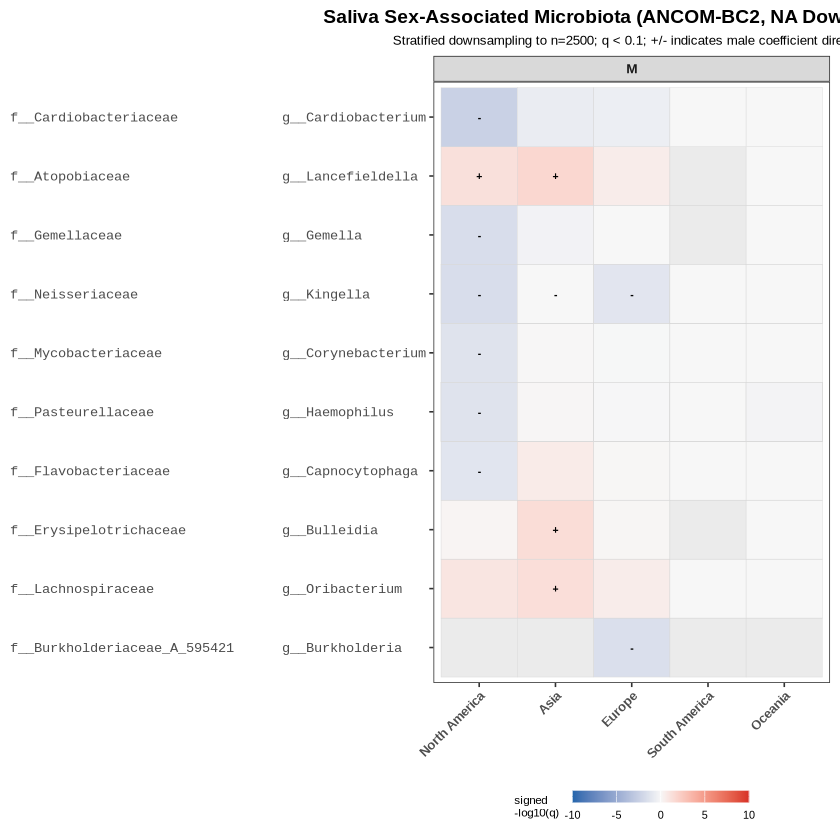

In [54]:
p_ancombc

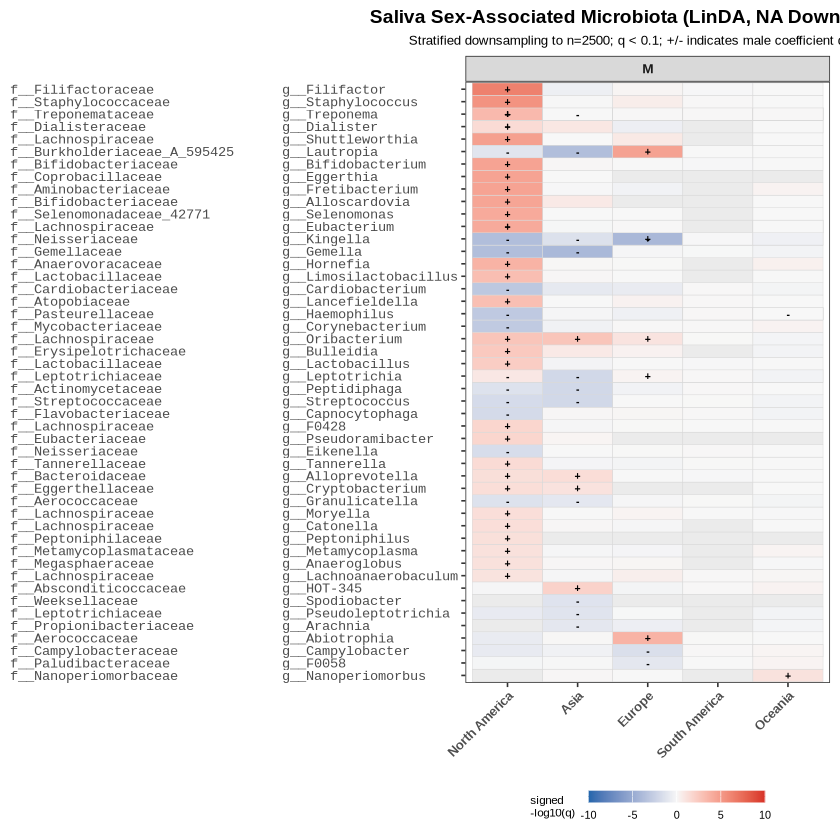

In [55]:
p_linda